# 02 · EMT-TF Expression — Gao et al. 2021 (Breast, 10x)

The EMT-transcription-factor readout is **unconditional** — produced regardless of the gate
outcome. Gate 1 was a **NO-GO** (the breast malignant compartment is a per-patient archipelago,
not a sample-integrated continuum; see 01), so no trajectory is fit and this is the *last*
notebook, numbered **02** (§6 renumbering: Gate 1 NO-GO -> 01 + 02).

We read the breast malignant cells from `processed.h5ad` and overlay the most informative EMT
transcription factors on the best-attempt manifold, gated on detectable expression. **No
pseudotime is available or claimed** (there is no valid trajectory).

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Gao2021_Breast-1 | category: Breast


### Load the processed breast malignant manifold (§6: expression reads `processed.h5ad`)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
adata.obs['sample'] = adata.obs['sample'].astype(str)
print('cells:', adata.shape[0], '| samples:', adata.obs['sample'].nunique(),
      '(', sorted(adata.obs['sample'].unique()), ')')
print('X max %.2f (log1p normalized)' % adata.X.max())

cells: 6411 | samples: 5 ( ['DCIS1', 'TNBC1', 'TNBC2', 'TNBC4', 'TNBC5'] )
X max 9.29 (log1p normalized)


### Derive the informative EMT-TFs (data-driven)
Candidate panel **widened beyond Snail/Zeb/Twist** to the FOXC and PRRX mesenchymal families
(evaluation lesson: the canonical panel alone can miss the informative factor). **VIM is
excluded** — vimentin is a mesenchymal *marker*, not a transcription factor (Chen-2020 lesson).
For each candidate: detection fraction and mean expression among expressers. With Gate 1 a NO-GO
there is no pseudotime, so factors are ranked by breadth of expression, and the two broadest
detectable factors (frac > 3%) are overlaid so the panel reflects real signal, not a handful of
dropout-driven cells.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]
    rows.append((g, round((x > 0).mean(), 3),
                 round(x[x > 0].mean() if (x > 0).any() else 0, 3), round(float(x.max()), 2)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_in_expr','max']).sort_values('frac_expr', ascending=False)
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].copy()
sel = ok.sort_values('frac_expr', ascending=False).head(2)['TF'].tolist()
print('\ndetectable EMT-TFs (frac>0.03):', ok.TF.tolist())
print('shown (two broadest):', sel)

    TF  frac_expr  mean_in_expr  max
 FOXC1      0.285         0.858 2.94
 FOXC2      0.165         0.533 2.13
 SNAI2      0.156         0.714 3.83
TWIST1      0.153         0.516 2.05
 PRRX1      0.144         0.680 2.54
 PRRX2      0.112         0.681 2.39
 SNAI1      0.097         0.349 1.75
  ZEB2      0.028         0.641 2.40
  ZEB1      0.012         0.503 2.24
TWIST2      0.003         0.597 1.14

detectable EMT-TFs (frac>0.03): ['FOXC1', 'FOXC2', 'SNAI2', 'TWIST1', 'PRRX1', 'PRRX2', 'SNAI1']
shown (two broadest): ['FOXC1', 'FOXC2']


### Deliverable — `expression.pdf` (categorical overlay, reference style)
Thresholded expressers of the two selected factors overlaid on a grey manifold — the reference
categorical style, **not** a continuous colormap (Sun-2021 binding lesson). Threshold = top
decile of expression among each factor's expressing cells, so a broadly-expressed TF is not
washed across the manifold.

overlay thresholds (top decile among expressers): {'FOXC1': 1.49, 'FOXC2': 1.04} | cells shown: {'FOXC1': 183, 'FOXC2': 106}
FOXC1: 28.5% expressing; 183 shown (top decile)
FOXC2: 16.5% expressing; 106 shown (top decile)
saved expression.pdf


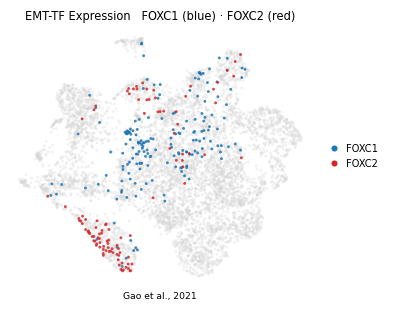

In [5]:
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()
thr = {}
for g in sel:
    v = _vec(g); pos = v[v > 0]; thr[g] = float(np.quantile(pos, 0.90)) if pos.size else 0.0
seln = {g: _vec(g) > thr[g] for g in sel}
print('overlay thresholds (top decile among expressers):', {g: round(thr[g], 2) for g in thr},
      '| cells shown:', {g: int(seln[g].sum()) for g in seln})
order = sorted(sel, key=lambda g: -int(seln[g].sum()))   # abundant first, sparser on top
colors = {sel[0]: 'tab:blue', sel[1]: 'tab:red'}
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, size=14, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[seln[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=14, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[g],markersize=5,label=g) for g in sel],
          loc='center left', bbox_to_anchor=(1.02, .5), frameon=False, fontsize=6.5, handletextpad=.2)
ax.set_title(f'EMT-TF Expression   {sel[0]} (blue) \u00b7 {sel[1]} (red)', size=7.5)
ax.text(.5, -.06, 'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in sel:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(seln[g].sum())} shown (top decile)')
print('saved expression.pdf')

*The overlay describes where the two most broadly-expressed EMT-TFs fall on the
best-attempt manifold. Because Gate 1 is a NO-GO, this is a descriptive expression map only — no
developmental ordering or root/terminus interpretation is attached to it.*